# COD Refusal Risk Model — Evaluation & Policy Economics

**UMKM E-Commerce COD Fraud & Return Risk Engine** — model evaluation notebook for the portfolio write-up.

This notebook loads the artifacts produced by `ml-pipeline/` (run `download_data.py → data_prep.py → features.py → train.py → calibrate.py` first) and produces every figure used in the report:

1. **Dataset & time split** — why we split by time, not randomly
2. **Discrimination** — ROC and Precision–Recall on the held-out test period
3. **Calibration** — why raw XGBoost probabilities are unusable, and how Platt scaling fixes them
4. **Domain-prior adjustment** — shifting Olist's 0.5% proxy base rate to an assumed 8% Indonesian COD refusal prior
5. **Feature importance & SHAP** — what the model actually looks at
6. **Policy economics** — the Smart Bouncer (green / yellow / red lanes) vs. naïve COD-for-all

> **Honesty note.** The label is a *proxy*: Olist `canceled`/`unavailable` orders stand in for COD refusals, which Olist (a Brazilian marketplace with prepayment) does not contain. All conclusions are about *methodology*, not about real Indonesian refusal rates.

## 0 · Setup

Paths default to the repo layout (`../ml-pipeline/...`); override with `ML_PROCESSED_DIR` / `ML_MODELS_DIR` if your artifacts live elsewhere.

In [1]:
import json
import os
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path("..").resolve() if (Path("..") / "ml-pipeline").exists() else Path(".").resolve()
SRC = ROOT / "ml-pipeline" / "src"
sys.path.insert(0, str(SRC))

PROCESSED = Path(os.environ.get("ML_PROCESSED_DIR", ROOT / "ml-pipeline" / "data" / "processed"))
MODELS    = Path(os.environ.get("ML_MODELS_DIR",    ROOT / "ml-pipeline" / "models"))
FIGURES   = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Dashboard palette (src/config/uiTheme.js) so report figures match the web app.
CLR = dict(primary="#F26522", accent="#1F9D55", warn="#F5A623", danger="#D64545",
           ink="#2B2118", surface="#FFF9F3", border="#F0E4D7", muted="#8A7B6C")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": CLR["border"], "axes.labelcolor": CLR["ink"],
    "text.color": CLR["ink"], "xtick.color": CLR["muted"], "ytick.color": CLR["muted"],
    "axes.grid": True, "grid.color": CLR["border"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "figure.dpi": 130,
})

def save(fig, name):
    fig.savefig(FIGURES / name, bbox_inches="tight")
    print(f"saved -> figures/{name}")

splits = pd.read_parquet(PROCESSED / "splits.parquet")
report = json.load(open(PROCESSED / "calibration_report.json"))
pipe   = joblib.load(MODELS / "xgb_calibrated.joblib")

DROP = {"order_id", "order_purchase_timestamp", "split", "split_role",
        "refused", "freight_value", "customer_state"}
FEATURE_COLS = [c for c in splits.columns if c not in DROP]

test = splits[splits.split_role == "test"].copy()
X_test = test[FEATURE_COLS].copy()
X_test["product_category"] = X_test["product_category"].astype("category")
y_test = test["refused"].to_numpy()

p_uncal = pipe.base_model.predict_proba(X_test)[:, 1]   # raw XGBoost (scale_pos_weight inflated)
p_cal   = pipe.predict_proba(X_test)                    # Platt-calibrated

print(f"test orders: {len(test):,} | refusals: {y_test.sum()} ({y_test.mean():.3%})")
print(f"features   : {len(FEATURE_COLS)}")

test orders: 12,581 | refusals: 71 (0.564%)
features   : 13


## 1 · Dataset & time-based split

We split **by time** (everything before 2018-07-01 → train/calibration, after → test), never randomly. A random split would leak future buyer/seller history into training and flatter every metric. The calibration slice is the *last 20% of the training period*, so the calibrator is fit on data the model never trained on.

saved -> figures/01_time_split.png


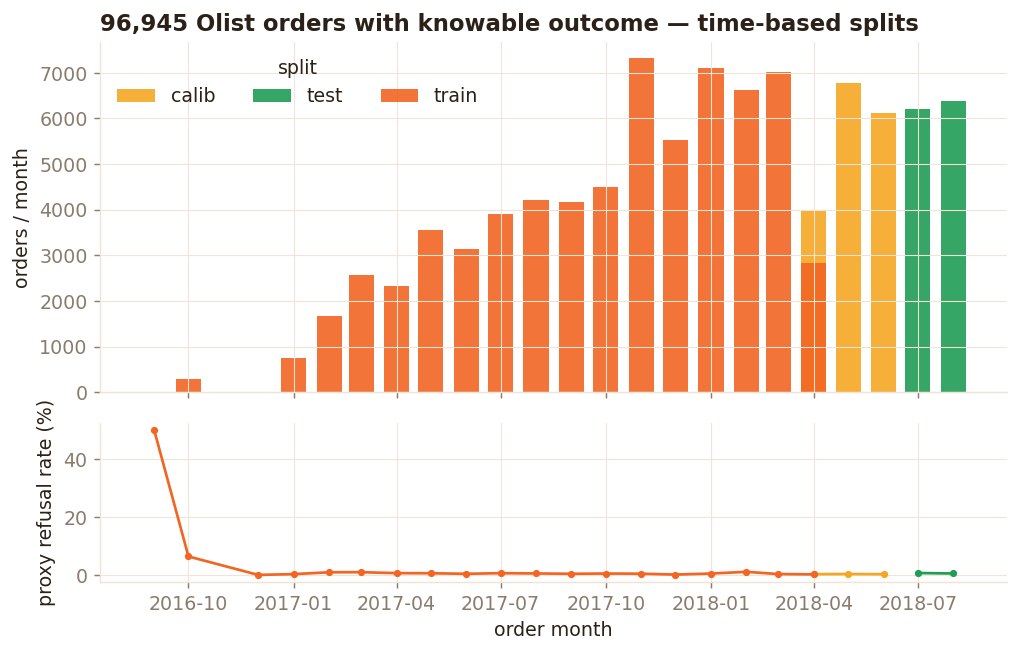

In [2]:
monthly = (splits.assign(month=pd.to_datetime(splits.order_purchase_timestamp).dt.to_period("M"))
                 .groupby(["month", "split_role"])
                 .agg(n=("refused", "size"), rate=("refused", "mean"))
                 .reset_index())
monthly["month"] = monthly["month"].dt.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True,
                               gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.12))
role_clr = {"train": CLR["primary"], "calib": CLR["warn"], "test": CLR["accent"]}
for role, g in monthly.groupby("split_role"):
    ax1.bar(g["month"], g["n"], width=22, color=role_clr[role], label=role, alpha=0.9)
    ax2.plot(g["month"], g["rate"] * 100, color=role_clr[role], marker="o", ms=3)
ax1.legend(frameon=False, title="split", ncols=3)
ax1.set_ylabel("orders / month")
ax2.set_ylabel("proxy refusal rate (%)")
ax2.set_xlabel("order month")
ax1.set_title("96,945 Olist orders with knowable outcome — time-based splits", loc="left", fontweight="bold")
save(fig, "01_time_split.png")
plt.show()

## 2 · Discrimination — ROC & Precision–Recall

With a 0.56% test base rate, ROC-AUC alone is flattering; the **Precision–Recall curve** (baseline = base rate) is the honest view. AUC ≈ 0.61 is *modest* — expected, since checkout-time features (no payment behaviour, no device fingerprint) carry limited signal. The model is a **ranking device**, not an oracle: its job is to push the worst few percent of orders into the DP/block lanes.

saved -> figures/02_discrimination.png


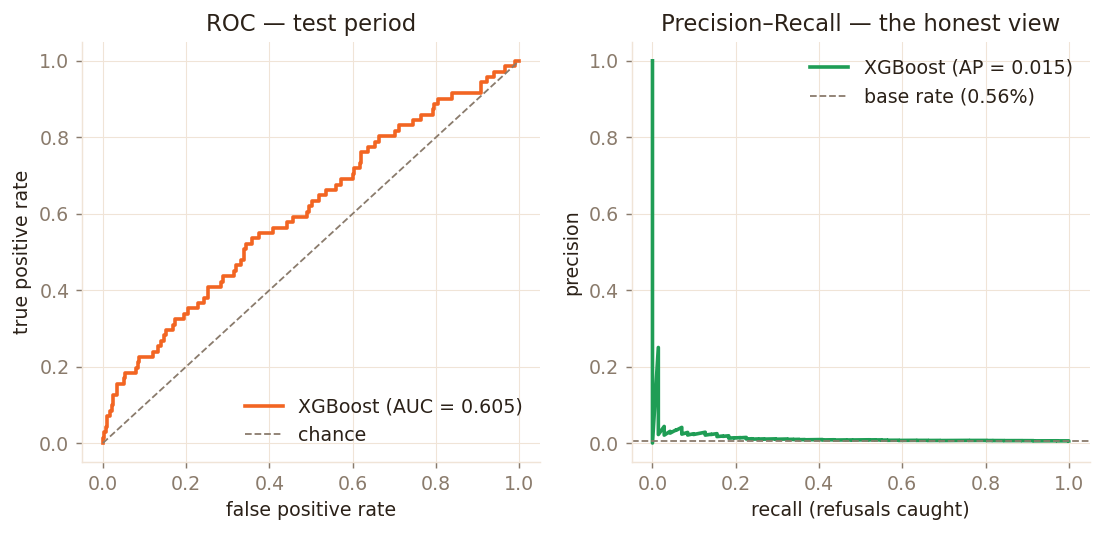

ROC-AUC = 0.6053 | Average precision = 0.0149 (2.6× the base rate)


In [3]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(y_test, p_cal)
prec, rec, _ = precision_recall_curve(y_test, p_cal)
roc_auc, ap = auc(fpr, tpr), average_precision_score(y_test, p_cal)
base = y_test.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.plot(fpr, tpr, color=CLR["primary"], lw=2, label=f"XGBoost (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], ls="--", color=CLR["muted"], lw=1, label="chance")
ax1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC — test period")
ax1.legend(frameon=False, loc="lower right")

ax2.plot(rec, prec, color=CLR["accent"], lw=2, label=f"XGBoost (AP = {ap:.3f})")
ax2.axhline(base, ls="--", color=CLR["muted"], lw=1, label=f"base rate ({base:.2%})")
ax2.set(xlabel="recall (refusals caught)", ylabel="precision", title="Precision–Recall — the honest view")
ax2.legend(frameon=False, loc="upper right")
save(fig, "02_discrimination.png")
plt.show()

print(f"ROC-AUC = {roc_auc:.4f} | Average precision = {ap:.4f} ({ap/base:.1f}× the base rate)")

## 3 · Calibration — from inflated scores to usable probabilities

`scale_pos_weight ≈ 191` fixes the 200:1 class imbalance for *ranking* but inflates raw probabilities ~18× (mean predicted 10.05% vs. true 0.56%). We fit **Platt (sigmoid)** and **isotonic** calibrators on the held-out calibration slice and pick the winner by **test-set Brier score**. Sigmoid wins — with only ~95 positives in the calibration slice, isotonic's extra flexibility just overfits.

The dashboard's routing thresholds only make sense on *calibrated* probabilities, so this step is what makes the whole policy layer meaningful.

/tmp/ipykernel_5202/528992326.py:18: RuntimeWarning: Mean of empty slice.
  return ([p[idx == b].mean() for b in range(n_bins)],
/usr/local/lib/python3.12/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_5202/528992326.py:19: RuntimeWarning: Mean of empty slice.
  [y[idx == b].mean() for b in range(n_bins)],
/usr/local/lib/python3.12/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


saved -> figures/03_calibration.png


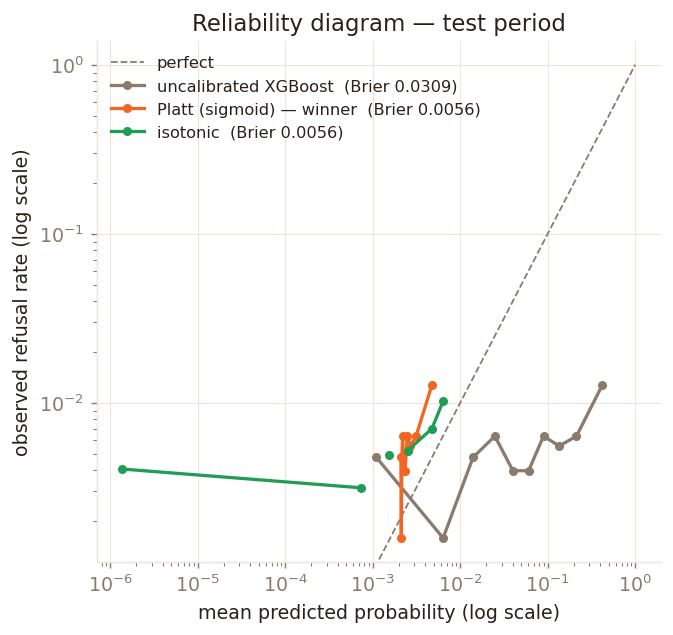

,variant,brier,mean_predicted
0,uncalibrated,0.03093,0.10052
1,sigmoid,0.00562,0.00263
2,isotonic,0.00562,0.00269


In [4]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

calib = splits[splits.split_role == "calib"]
X_c = calib[FEATURE_COLS].copy(); X_c["product_category"] = X_c["product_category"].astype("category")
y_c = calib["refused"].to_numpy()
p_c_raw = pipe.base_model.predict_proba(X_c)[:, 1]

sig = LogisticRegression(C=1.0, solver="lbfgs").fit(p_c_raw.reshape(-1, 1), y_c)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_c_raw, y_c)
p_sig = sig.predict_proba(p_uncal.reshape(-1, 1))[:, 1]
p_iso = iso.predict(p_uncal)

def reliability(y, p, n_bins=10):
    qs = np.quantile(p, np.linspace(0, 1, n_bins + 1)); qs[0], qs[-1] = 0, 1
    idx = np.clip(np.digitize(p, qs[1:-1]), 0, n_bins - 1)
    return ([p[idx == b].mean() for b in range(n_bins)],
            [y[idx == b].mean() for b in range(n_bins)],
            [(idx == b).sum() for b in range(n_bins)])

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], ls="--", color=CLR["muted"], lw=1, label="perfect")
for p, name, c in [(p_uncal, "uncalibrated XGBoost", CLR["muted"]),
                   (p_sig,   "Platt (sigmoid) — winner", CLR["primary"]),
                   (p_iso,   "isotonic", CLR["accent"])]:
    px, py, n = reliability(y_test, p)
    ax.plot(px, py, marker="o", ms=4, lw=1.8, color=c,
            label=f"{name}  (Brier {brier_score_loss(y_test, p):.4f})")
ax.set(xscale="log", yscale="log", xlabel="mean predicted probability (log scale)",
       ylabel="observed refusal rate (log scale)", title="Reliability diagram — test period")
ax.legend(frameon=False, fontsize=9, loc="upper left")
save(fig, "03_calibration.png")
plt.show()

pd.DataFrame({"variant": ["uncalibrated", "sigmoid", "isotonic"],
              "brier": [brier_score_loss(y_test, p) for p in (p_uncal, p_sig, p_iso)],
              "mean_predicted": [p_uncal.mean(), p_sig.mean(), p_iso.mean()]}).round(5)

## 4 · Domain-prior adjustment — from a Brazilian proxy to an Indonesian prior

Olist has almost no real COD, so even after calibration the test base rate is 0.56%. Indonesian e-commerce COD refusal is commonly estimated in the **5–10%** range. Rather than pretend the proxy *is* the real rate, we shift probabilities on the **logit scale** (a pure intercept move) until the portfolio mean matches an assumed 8% prior:

$$p' = \sigma\big(\text{logit}(p) + \delta\big) \quad\text{with } \delta \text{ chosen so } \mathbb{E}[p'] = 0.08$$

Ranking (and therefore AUC) is **unchanged** — only the level moves, which is what the policy thresholds consume. This is disclosed as an *assumption* in the dashboard, not smuggled in as data.

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


saved -> figures/04_prior_shift.png


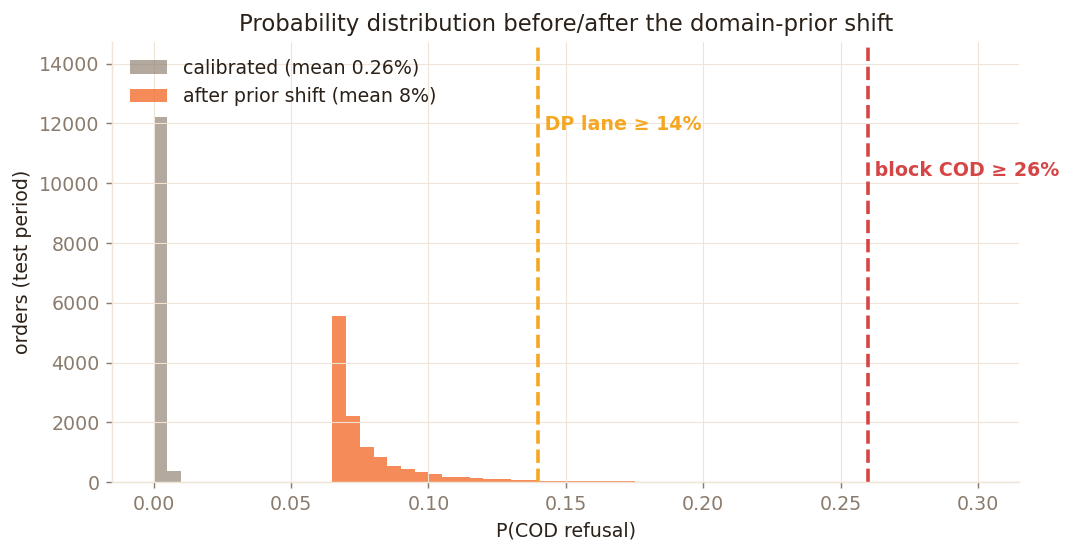

,orders,share
APPROVE_COD,12173,4057.667
REQUIRE_DP,404,134.667
BLOCK_COD,4,1.333


In [5]:
from export_json import shift_to_base_rate, TARGET_REFUSAL_BASE_RATE

p_adj = shift_to_base_rate(p_cal, TARGET_REFUSAL_BASE_RATE)

DP_T, BLOCK_T = 0.14, 0.26
fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.linspace(0, 0.30, 61)
ax.hist(p_cal, bins=bins, alpha=0.65, color=CLR["muted"],
        label=f"calibrated (mean {p_cal.mean():.2%})")
ax.hist(p_adj, bins=bins, alpha=0.75, color=CLR["primary"],
        label=f"after prior shift (mean {p_adj.mean():.0%})")
ax.axvline(DP_T, color=CLR["warn"], lw=2, ls="--")
ax.axvline(BLOCK_T, color=CLR["danger"], lw=2, ls="--")
ax.text(DP_T, ax.get_ylim()[1]*0.92, " DP lane ≥ 14%", color=CLR["warn"], fontweight="bold")
ax.text(BLOCK_T, ax.get_ylim()[1]*0.80, " block COD ≥ 26%", color=CLR["danger"], fontweight="bold")
ax.set(xlabel="P(COD refusal)", ylabel="orders (test period)",
       title="Probability distribution before/after the domain-prior shift", ylim=(0, ax.get_ylim()[1]*1.15))
ax.legend(frameon=False)
save(fig, "04_prior_shift.png")
plt.show()

lanes = pd.cut(p_adj, [-1, DP_T, BLOCK_T, 1], labels=["APPROVE_COD", "REQUIRE_DP", "BLOCK_COD"])
lanes.value_counts().to_frame("orders").assign(share=lambda d: (d.orders/len(d)).round(3))

## 5 · What the model looks at

Two complementary views: **gain importance** (how much each feature contributes to splits) and **SHAP values** (direction *and* magnitude per order, on a 5,000-order test sample). The same SHAP machinery powers the per-order explanations in the dashboard's Order Inspector.

Note the honesty constraint: behavioural history features (`buyer_prior_*`, `seller_refusal_rate`, `state_refusal_rate`) are computed with **strictly expanding windows** — each order only sees what happened *before* it.

saved -> figures/05_importance.png


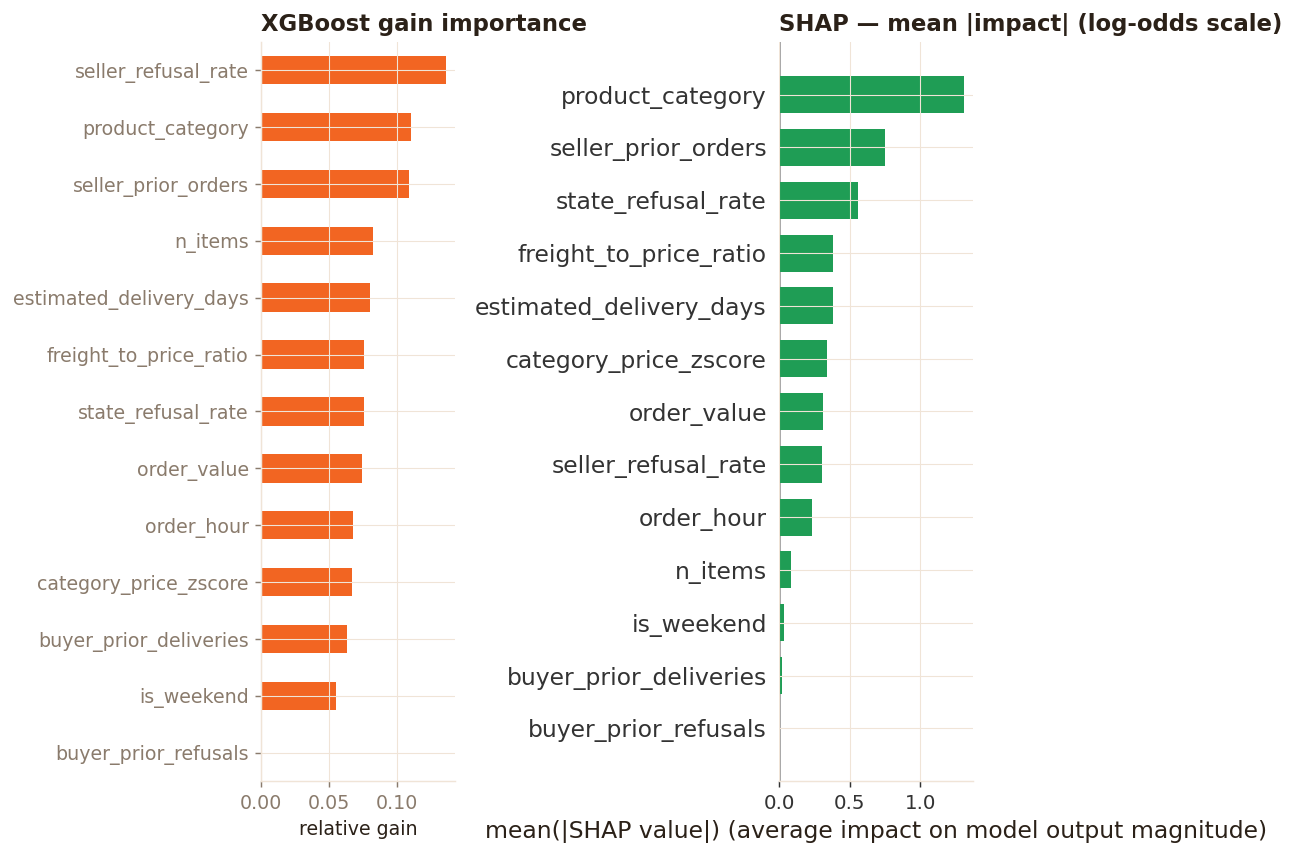

In [6]:
import shap

rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), size=5000, replace=False)
X_shap = X_test.iloc[idx]

explainer = shap.TreeExplainer(pipe.base_model)
sv = explainer.shap_values(X_shap)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
imp = pd.Series(pipe.base_model.feature_importances_, index=FEATURE_COLS).sort_values()
imp.plot.barh(ax=ax1, color=CLR["primary"])
ax1.set_title("XGBoost gain importance", loc="left", fontweight="bold")
ax1.set_xlabel("relative gain")

plt.sca(ax2)
shap.summary_plot(sv, X_shap, plot_type="bar", show=False, color=CLR["accent"], max_display=13)
ax2.set_title("SHAP — mean |impact| (log-odds scale)", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "05_importance.png")
plt.show()

saved -> figures/06_shap_beeswarm.png


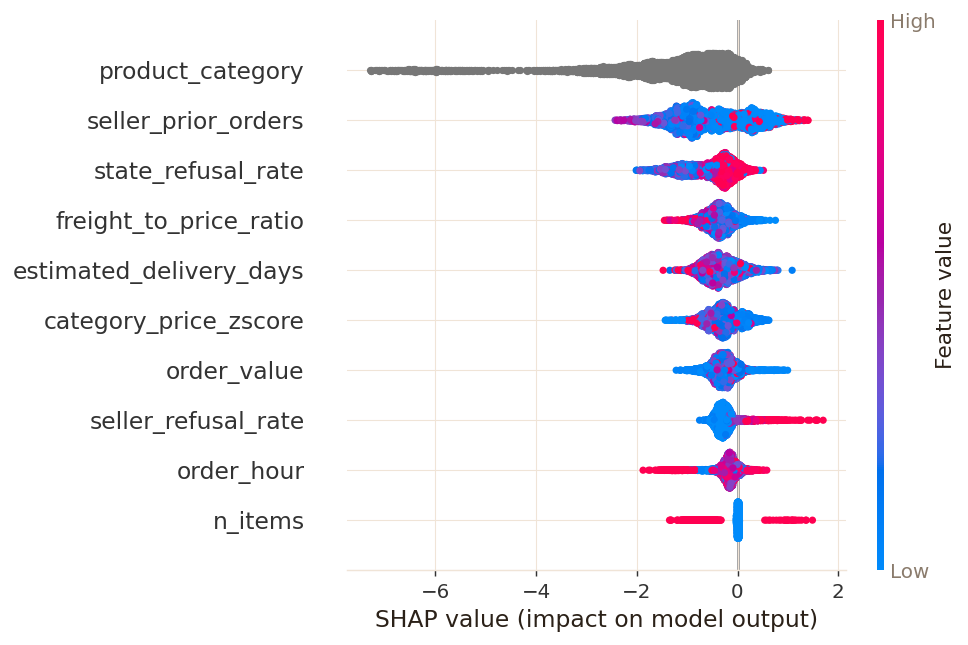

In [7]:
shap.summary_plot(sv, X_shap, show=False, max_display=10)
fig = plt.gcf(); fig.set_size_inches(7.5, 5)
save(fig, "06_shap_beeswarm.png")
plt.show()

## 6 · Policy economics — the Smart Bouncer

The routing logic lives in `web/src/utils/riskEngine.js`; this cell mirrors it exactly (same formulas, same defaults) so the report and the dashboard can never drift apart:

$$EP_{COD} = (1-p)\cdot \text{margin} \;-\; p\cdot (\text{returnShip} + \text{packaging} + \text{capitalHold})$$

- **Green lane** (`APPROVE_COD`): $EP_{COD} \ge 0$ and $p < 14\%$
- **Yellow lane** (`REQUIRE_DP`): $p \in [14\%, 26\%)$ and the Rp 25.000 deposit deters 15% of refusals *and* cushions the rest
- **Red lane** (`BLOCK_COD`): $p \ge 26\%$ — but blocked ≠ lost: 70% of blocked buyers convert to prepaid, so the engine earns $0.70\cdot(1-p)\cdot\text{margin}$ on them

We compare against the **naïve baseline** (approve COD for everyone) under three scenarios: default, a Harbolnas 11.11 stress test (refusals ×1.8, margin −8pp, +4 capital-hold days), and an extreme version (×2.5, −12pp, +7 days).

saved -> figures/07_policy_economics.png


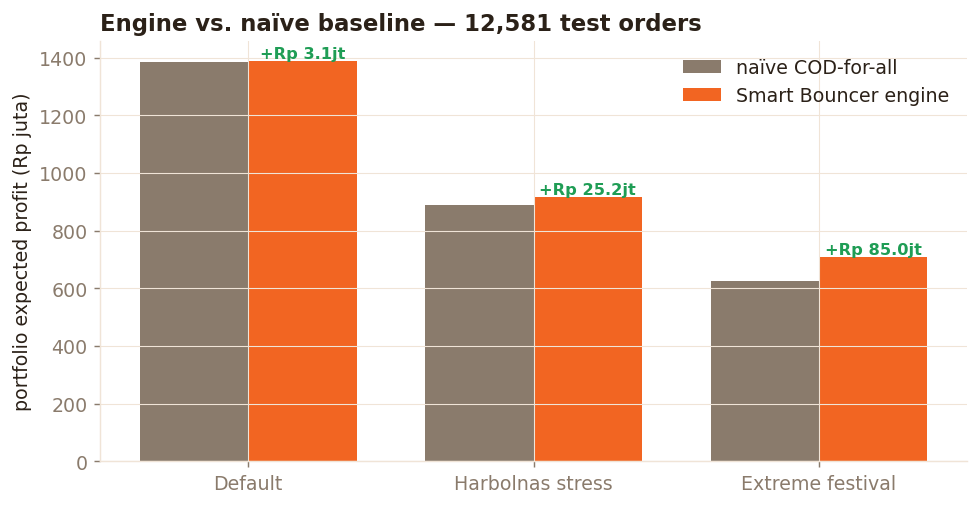

,scenario,naive,engine,protected
0,Default,1.385280e+09,1.388392e+09,3111273.0
1,Harbolnas stress,8.906230e+08,9.158284e+08,25205349.0
2,Extreme festival,6.249976e+08,7.099822e+08,84984591.0


In [8]:
BRL_TO_IDR = 3000
A = dict(gross_margin=0.30, return_ship=35_000, packaging=10_000,
         hold_daily=0.0005, hold_days=14, deposit=25_000,
         dp_deterrence=0.15, prepay_conv=0.70)

def refusal_loss(v, a):
    return a["return_ship"] + a["packaging"] + a["hold_daily"] * a["hold_days"] * v

def ep_cod(p, v, a):     return (1-p) * v*a["gross_margin"] - p * refusal_loss(v, a)
def ep_dp(p, v, a):
    pa = p * (1 - a["dp_deterrence"])
    return (1-pa) * v*a["gross_margin"] - pa * max(refusal_loss(v, a) - a["deposit"], 0)
def ep_blocked(p, v, a): return a["prepay_conv"] * (1-p) * v * a["gross_margin"]

def route(p, v, a, dp_t=DP_T, block_t=BLOCK_T):
    c, d = ep_cod(p, v, a), ep_dp(p, v, a)
    if p >= block_t or (c < 0 and d < 0): return "BLOCK_COD"
    if c < 0 or (p >= dp_t and d > c):    return "REQUIRE_DP"
    return "APPROVE_COD"

def portfolio(p, v, a):
    engine, naive = 0.0, 0.0
    lanes = {"APPROVE_COD": 0, "REQUIRE_DP": 0, "BLOCK_COD": 0}
    for pi, vi in zip(p, v):
        naive += ep_cod(pi, vi, a)
        pol = route(pi, vi, a)
        lanes[pol] += 1
        engine += {"APPROVE_COD": ep_cod, "REQUIRE_DP": ep_dp, "BLOCK_COD": ep_blocked}[pol](pi, vi, a)
    return engine, naive, lanes

v_idr = (test["order_value"] * BRL_TO_IDR).to_numpy()

scenarios = {
    "Default":            (p_adj,         A),
    "Harbolnas stress":   (np.clip(p_adj*1.8, 0, 0.95), {**A, "gross_margin": 0.22, "hold_days": 18}),
    "Extreme festival":   (np.clip(p_adj*2.5, 0, 0.95), {**A, "gross_margin": 0.18, "hold_days": 21}),
}
rows, lane_rows = [], {}
for name, (p_s, a_s) in scenarios.items():
    eng, nai, lanes = portfolio(p_s, v_idr, a_s)
    rows.append(dict(scenario=name, naive=nai, engine=eng, protected=eng-nai))
    lane_rows[name] = lanes
res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.6, 4.2))
x = np.arange(len(res)); w = 0.38
ax.bar(x - w/2, res.naive/1e6, w, color=CLR["muted"], label="naïve COD-for-all")
ax.bar(x + w/2, res.engine/1e6, w, color=CLR["primary"], label="Smart Bouncer engine")
for i, r in res.iterrows():
    ax.text(i + w/2, r.engine/1e6, f"+Rp {r.protected/1e6:,.1f}jt".replace(",", "."),
            ha="center", va="bottom", fontsize=9, fontweight="bold", color=CLR["accent"])
ax.set_xticks(x, res.scenario)
ax.set_ylabel("portfolio expected profit (Rp juta)")
ax.set_title("Engine vs. naïve baseline — 12,581 test orders", loc="left", fontweight="bold")
ax.legend(frameon=False)
save(fig, "07_policy_economics.png")
plt.show()

res.round(0)

saved -> figures/08_lane_migration.png


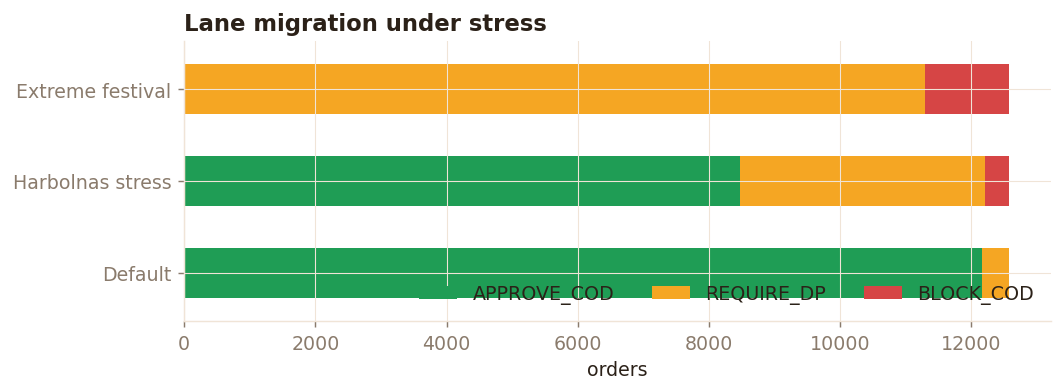

,APPROVE_COD,REQUIRE_DP,BLOCK_COD
Default,12170,407,4
Harbolnas stress,8471,3733,377
Extreme festival,0,11290,1291


In [9]:
lanes_df = pd.DataFrame(lane_rows).T[["APPROVE_COD", "REQUIRE_DP", "BLOCK_COD"]]
lanes_df.plot.barh(stacked=True, color=[CLR["accent"], CLR["warn"], CLR["danger"]],
                   figsize=(8.6, 2.8), width=0.55)
plt.xlabel("orders"); plt.title("Lane migration under stress", loc="left", fontweight="bold")
plt.legend(frameon=False, ncols=3, loc="lower right")
save(plt.gcf(), "08_lane_migration.png")
plt.show()
lanes_df

## 7 · Limitations — said out loud

1. **Proxy label.** `canceled`/`unavailable` on a prepaid Brazilian marketplace ≠ Indonesian COD refusal. It preserves *ordering* signal, not *level* — hence the explicit 8% prior assumption, disclosed in the UI.
2. **Modest discrimination.** AUC 0.61 is what checkout-only features buy you. A production system would add device fingerprinting, courier telemetry, and payment-attempt history — all deliberately out of scope here (leakage / availability).
3. **Static thresholds.** The 14% / 26% lanes are tuned on this test period; a real deployment would re-fit them on a profit curve per category.
4. **Single marketplace, 2016–2018.** Olist stops at late 2018; consumer behaviour has moved on.

## Reproduce

```bash
cd ml-pipeline/src
python download_data.py && python data_prep.py && python features.py
python train.py && python calibrate.py && python export_json.py
```

Then run this notebook from `notebooks/`. All figures land in `notebooks/figures/`.